# Tugas Pertemuan 9 Basic Deep Learning



In [1]:
!pip install tensorflow-cpu scikit-learn matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.3/274.3 MB 40.5 MB/s  0:00:06


### 1. Load Dataset


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

dataset_dir = "/content/dataset"
classes = sorted(os.listdir(dataset_dir))
img_size = 128

X, y = [], []
for idx, label in enumerate(classes):
    folder = os.path.join(dataset_dir, label)
    for f in os.listdir(folder):
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            img = keras.utils.load_img(os.path.join(folder, f), target_size=(img_size, img_size))
            X.append(keras.utils.img_to_array(img))
            y.append(idx)

X = np.array(X) / 255.0
y = np.array(y)
print(X.shape, dict(zip(classes, np.bincount(y).tolist())))

(280, 128, 128, 3) {'bacterial_spot': 70, 'healthy': 70, 'powdery': 70, 'virus': 70}


Contoh gambar tiap kelas.

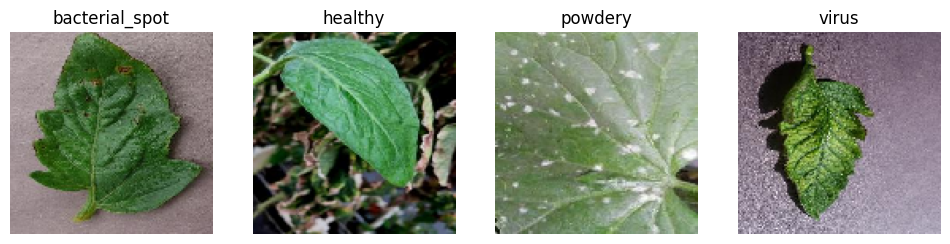

In [5]:
fig, axes = plt.subplots(1, len(classes), figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(X[np.where(y == i)[0][0]])
    ax.set_title(classes[i])
    ax.axis("off")
plt.show()

### 2. Split Data

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (224, 128, 128, 3) Test: (56, 128, 128, 3)


### 3. Arsitektur CNN Sederhana
- Augmentasi
- ekstraksi fitur

In [7]:
keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(img_size, img_size, 3)),
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.1),
    keras.layers.Conv2D(32, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(len(classes), activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Training


In [8]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=16,
    callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)],
)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 562ms/step - accuracy: 0.2961 - loss: 1.3842 - val_accuracy: 0.2444 - val_loss: 1.1690
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 694ms/step - accuracy: 0.5084 - loss: 1.1035 - val_accuracy: 0.5111 - val_loss: 0.7846
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - accuracy: 0.5922 - loss: 0.8375 - val_accuracy: 0.7111 - val_loss: 0.5592
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 521ms/step - accuracy: 0.7486 - loss: 0.7059 - val_accuracy: 0.9556 - val_loss: 0.3076
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 12s 599ms/step - accuracy: 0.7654 - loss: 0.5854 - val_accuracy: 0.8000 - val_loss: 0.4104
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 654ms/step - accuracy: 0.7989 - loss: 0.4793 - val_accuracy: 0.8000 - val_loss: 0.4266
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 497ms/step - accuracy: 0.7877 - loss: 0.4958 - val_accuracy: 0.7778 - val_loss: 0.4806
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 667ms/step - accuracy: 0.8603 - loss: 0.4088 - val_accuracy

Grafik accuracy dan loss

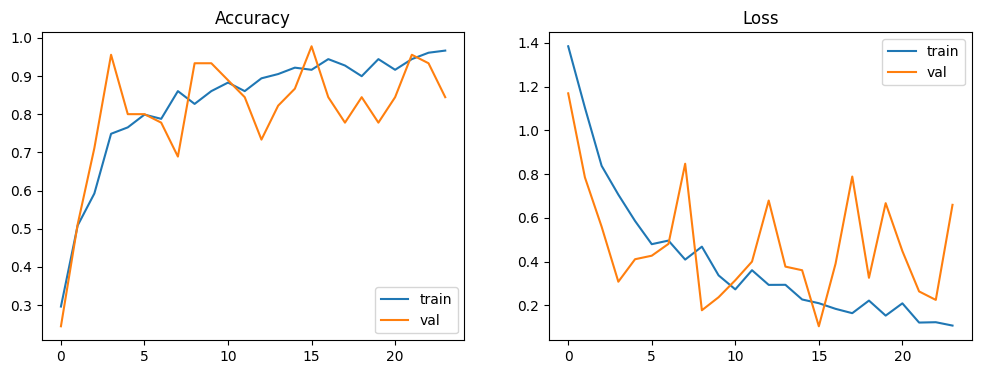

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history["accuracy"], label="train")
ax1.plot(history.history["val_accuracy"], label="val")
ax1.set_title("Accuracy")
ax1.legend()
ax2.plot(history.history["loss"], label="train")
ax2.plot(history.history["val_loss"], label="val")
ax2.set_title("Loss")
ax2.legend()
plt.show()

### 5. Evaluasi


In [10]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, ConfusionMatrixDisplay

y_pred = model.predict(X_test).argmax(axis=1)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

pd.DataFrame(
    {"Accuracy": [acc], "Precision": [prec], "Recall": [rec], "F1-Score": [f1]},
    index=["CNN"],
).round(4)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 482ms/step


,Accuracy,Precision,Recall,F1-Score
CNN,0.9107,0.9143,0.9107,0.9119


                precision    recall  f1-score   support

bacterial_spot       1.00      0.93      0.96        14
       healthy       0.86      0.86      0.86        14
       powdery       0.80      0.86      0.83        14
         virus       1.00      1.00      1.00        14

      accuracy                           0.91        56
     macro avg       0.91      0.91      0.91        56
  weighted avg       0.91      0.91      0.91        56



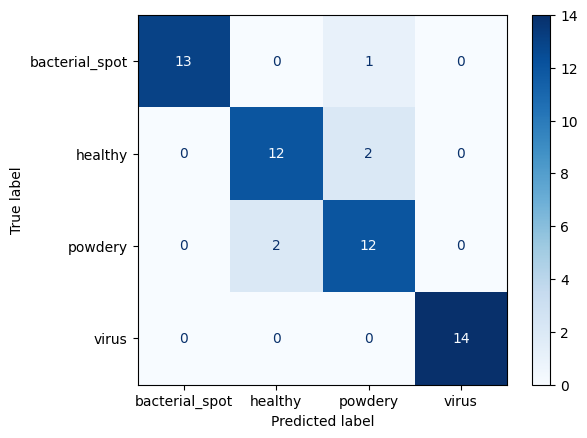

In [11]:
print(classification_report(y_test, y_pred, target_names=classes, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=classes, cmap="Blues")
plt.show()